In [1]:
import pandas as pd
df = pd.read_csv("creditcard.csv")

print("Shape:", df.shape)
print("\nMissing values:", df.isnull().sum().sum())
print("\nFraud vs genuine:")
print(df["Class"].value_counts())
print("\nFraud percentage:", round(df["Class"].mean() * 100, 3), "%")
df.head()

Shape: (284807, 31)

Missing values: 0

Fraud vs genuine:
Class
0    284315
1       492
Name: count, dtype: int64

Fraud percentage: 0.173 %


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      284315.0   88.29  250.11  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.21  256.68  0.0  1.00   9.25  105.89   2125.87


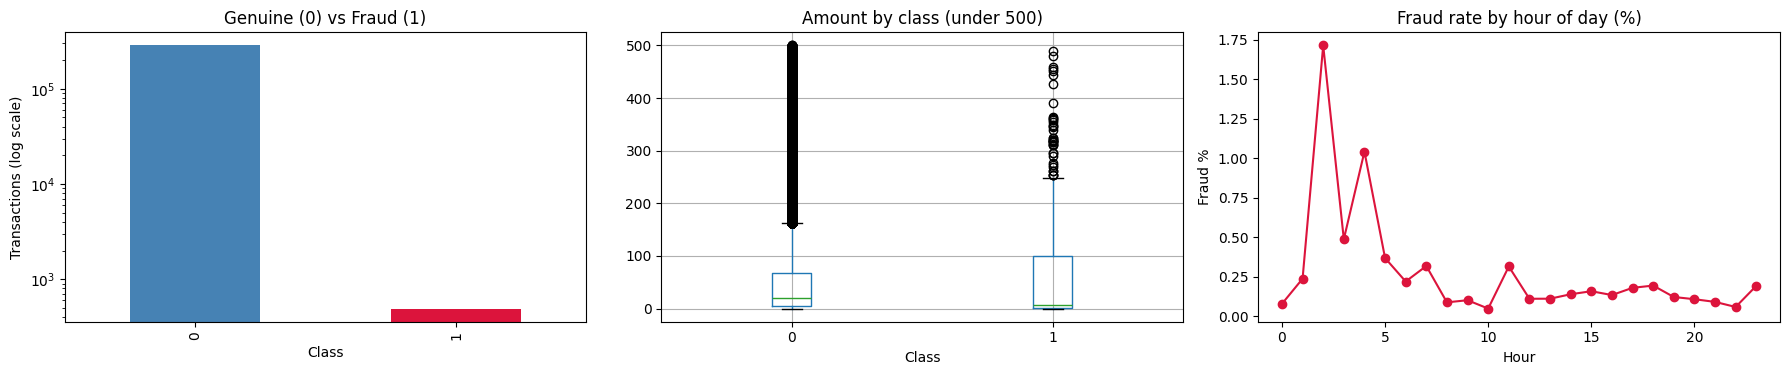

In [2]:
import matplotlib.pyplot as plt

# Amount comparison
print(df.groupby("Class")["Amount"].describe().round(2))

# Hour of day (Time is seconds since the first transaction, over 2 days)
df["Hour"] = (df["Time"] // 3600) % 24

fig, ax = plt.subplots(1, 3, figsize=(18, 4))

# 1. Class imbalance
df["Class"].value_counts().plot(kind="bar", ax=ax[0], color=["steelblue", "crimson"])
ax[0].set_title("Genuine (0) vs Fraud (1)")
ax[0].set_yscale("log")
ax[0].set_ylabel("Transactions (log scale)")

# 2. Amount distribution by class
df[df["Amount"] < 500].boxplot(column="Amount", by="Class", ax=ax[1])
ax[1].set_title("Amount by class (under 500)")
ax[1].set_xlabel("Class")

# 3. Fraud rate by hour
(df.groupby("Hour")["Class"].mean() * 100).plot(ax=ax[2], marker="o", color="crimson")
ax[2].set_title("Fraud rate by hour of day (%)")
ax[2].set_ylabel("Fraud %")

plt.suptitle("")
plt.tight_layout()
plt.savefig("eda_overview.png", dpi=150)
plt.show()

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             average_precision_score, roc_auc_score)

# Prepare features
X = df.drop(columns=["Class", "Time", "Hour"])
y = df["Class"]
X["Amount"] = RobustScaler().fit_transform(X[["Amount"]])

# Split (stratify keeps the same fraud % in both sets)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# Train
model = LogisticRegression(class_weight="balanced", max_iter=1000)
model.fit(X_train, y_train)

# Evaluate
pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]

print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred, digits=3))
print("PR-AUC:", round(average_precision_score(y_test, proba), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))

[[55423  1441]
 [    8    90]]
              precision    recall  f1-score   support

           0      1.000     0.975     0.987     56864
           1      0.059     0.918     0.110        98

    accuracy                          0.975     56962
   macro avg      0.529     0.947     0.549     56962
weighted avg      0.998     0.975     0.986     56962

PR-AUC: 0.716
ROC-AUC: 0.971


In [4]:
from sklearn.ensemble import RandomForestClassifier
import numpy as np, pandas as pd

# Second model
rf = RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                            n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
rf_proba = rf.predict_proba(X_test)[:, 1]

print("PR-AUC  LogReg:", round(average_precision_score(y_test, proba), 3))
print("PR-AUC  RandomForest:", round(average_precision_score(y_test, rf_proba), 3))

# Business cost (ASSUMPTIONS: edit these and say so in your README)
MISSED_FRAUD_COST = 122   # average fraud amount from your analysis
FALSE_ALERT_COST = 5      # assumed cost of a manual review

def cost_table(name, p):
    rows = []
    for t in [0.1, 0.3, 0.5, 0.7, 0.8, 0.9, 0.95, 0.99]:
        pred_t = (p >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, pred_t).ravel()
        rows.append({"model": name, "threshold": t, "caught": tp, "missed": fn,
                     "false_alerts": fp,
                     "total_cost": fn * MISSED_FRAUD_COST + fp * FALSE_ALERT_COST})
    return pd.DataFrame(rows)

results = pd.concat([cost_table("LogReg", proba), cost_table("RandomForest", rf_proba)])
print(results.to_string(index=False))
print("\nCost with NO model:", int(y_test.sum() * MISSED_FRAUD_COST))

PR-AUC  LogReg: 0.716
PR-AUC  RandomForest: 0.858
       model  threshold  caught  missed  false_alerts  total_cost
      LogReg       0.10      93       5         11353       57375
      LogReg       0.30      90       8          3273       17341
      LogReg       0.50      90       8          1441        8181
      LogReg       0.70      88      10           667        4555
      LogReg       0.80      88      10           445        3445
      LogReg       0.90      87      11           262        2652
      LogReg       0.95      87      11           132        2002
      LogReg       0.99      83      15            62        2140
RandomForest       0.10      87      11            28        1482
RandomForest       0.30      79      19             8        2358
RandomForest       0.50      74      24             4        2948
RandomForest       0.70      67      31             2        3792
RandomForest       0.80      61      37             2        4524
RandomForest       0.90   

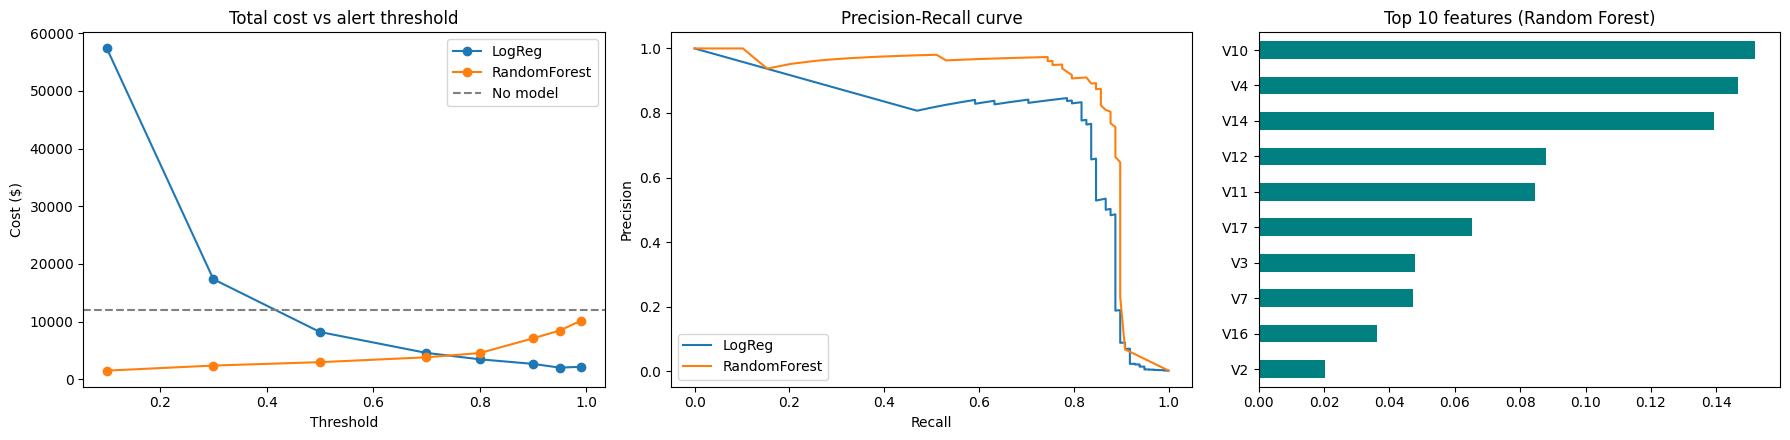

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

# 1. Cost vs threshold
for name, grp in results.groupby("model"):
    ax[0].plot(grp["threshold"], grp["total_cost"], marker="o", label=name)
ax[0].axhline(y_test.sum() * MISSED_FRAUD_COST, color="grey", linestyle="--", label="No model")
ax[0].set_title("Total cost vs alert threshold")
ax[0].set_xlabel("Threshold"); ax[0].set_ylabel("Cost ($)"); ax[0].legend()

# 2. Precision-Recall curves
for name, p in [("LogReg", proba), ("RandomForest", rf_proba)]:
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rc, pr, label=name)
ax[1].set_title("Precision-Recall curve")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].legend()

# 3. Top 10 features (Random Forest)
imp = pd.Series(rf.feature_importances_, index=X.columns).nlargest(10)[::-1]
imp.plot(kind="barh", ax=ax[2], color="teal")
ax[2].set_title("Top 10 features (Random Forest)")

plt.tight_layout()
plt.savefig("model_results.png", dpi=150)
plt.show()

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
import numpy as np, pandas as pd

# Split the training data again: 75% to fit, 25% to choose the threshold
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=42)

rf2 = RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                             n_jobs=-1, random_state=42)
rf2.fit(X_fit, y_fit)
val_p = rf2.predict_proba(X_val)[:, 1]
test_p = rf2.predict_proba(X_test)[:, 1]

thresholds = np.arange(0.02, 1.0, 0.02)

def total_cost(y_true, p, t, c_fraud, c_alert):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return fn * c_fraud + fp * c_alert, tp, fn, fp

def best_threshold(c_fraud, c_alert):
    costs = [total_cost(y_val, val_p, t, c_fraud, c_alert)[0] for t in thresholds]
    return thresholds[int(np.argmin(costs))]

# Threshold chosen on validation, cost measured once on test
t_best = best_threshold(122, 5)
cost, tp, fn, fp = total_cost(y_test, test_p, t_best, 122, 5)
no_model = int(y_test.sum() * 122)

print("Threshold chosen on validation:", round(t_best, 2))
print("Test set -> caught:", tp, "| missed:", fn, "| false alerts:", fp)
print("Test cost:", int(cost), "| No-model cost:", no_model)
print("Saving:", round(100 * (1 - cost / no_model), 1), "%")


Threshold chosen on validation: 0.04
Test set -> caught: 87 | missed: 11 | false alerts: 79
Test cost: 1737 | No-model cost: 11956
Saving: 85.5 %


In [7]:
rows = []
for c_fraud in [50, 122, 300]:
    for c_alert in [2, 5, 20]:
        t = best_threshold(c_fraud, c_alert)
        cost, tp, fn, fp = total_cost(y_test, test_p, t, c_fraud, c_alert)
        base = int(y_test.sum() * c_fraud)
        rows.append({"fraud_cost": c_fraud, "review_cost": c_alert,
                     "best_threshold": round(t, 2), "caught": tp, "missed": fn,
                     "false_alerts": fp, "model_cost": int(cost),
                     "no_model_cost": base,
                     "saving_pct": round(100 * (1 - cost / base), 1)})

sens = pd.DataFrame(rows)
print(sens.to_string(index=False))
sens.to_csv("sensitivity_analysis.csv", index=False)


 fraud_cost  review_cost  best_threshold  caught  missed  false_alerts  model_cost  no_model_cost  saving_pct
         50            2            0.04      87      11            79         708           4900        85.6
         50            5            0.08      85      13            31         805           4900        83.6
         50           20            0.24      82      16            12        1040           4900        78.8
        122            2            0.04      87      11            79        1500          11956        87.5
        122            5            0.04      87      11            79        1737          11956        85.5
        122           20            0.08      85      13            31        2206          11956        81.5
        300            2            0.04      87      11            79        3458          29400        88.2
        300            5            0.04      87      11            79        3695          29400        87.4
        30

In [8]:
import sqlite3, pandas as pd

raw = pd.read_csv("creditcard.csv")
conn = sqlite3.connect(":memory:")
raw.to_sql("transactions", conn, index=False)
q = lambda s: pd.read_sql(s, conn)

# Q1: Overall fraud rate and fraud value
print(q("""
SELECT COUNT(*) AS transactions,
       SUM(Class) AS frauds,
       ROUND(100.0 * SUM(Class) / COUNT(*), 3) AS fraud_rate_pct,
       ROUND(SUM(CASE WHEN Class = 1 THEN Amount END), 2) AS fraud_value
FROM transactions
"""))

# Q2: Fraud rate by amount bucket
print(q("""
SELECT CASE WHEN Amount <= 1 THEN '1. $0-1'
            WHEN Amount <= 10 THEN '2. $1-10'
            WHEN Amount <= 100 THEN '3. $10-100'
            WHEN Amount <= 500 THEN '4. $100-500'
            ELSE '5. $500+' END AS amount_bucket,
       COUNT(*) AS transactions,
       SUM(Class) AS frauds,
       ROUND(100.0 * SUM(Class) / COUNT(*), 3) AS fraud_rate_pct
FROM transactions
GROUP BY amount_bucket
ORDER BY amount_bucket
"""))

# Q3: Top 5 riskiest hours (window function ranking)
print(q("""
WITH hourly AS (
  SELECT CAST(Time AS INTEGER) / 3600 % 24 AS hr,
         COUNT(*) AS transactions,
         SUM(Class) AS frauds,
         100.0 * SUM(Class) / COUNT(*) AS fraud_rate_pct
  FROM transactions
  GROUP BY hr
)
SELECT hr, transactions, frauds, ROUND(fraud_rate_pct, 3) AS fraud_rate_pct,
       RANK() OVER (ORDER BY fraud_rate_pct DESC) AS risk_rank
FROM hourly
ORDER BY risk_rank
LIMIT 5
"""))

# Q4: Small-amount fraud (possible card testing)
print(q("""
SELECT COUNT(*) AS small_frauds,
       ROUND(100.0 * COUNT(*) / (SELECT SUM(Class) FROM transactions), 1) AS pct_of_all_fraud
FROM transactions
WHERE Class = 1 AND Amount <= 1
"""))

   transactions  frauds  fraud_rate_pct  fraud_value
0        284807     492           0.173     60127.97
  amount_bucket  transactions  frauds  fraud_rate_pct
0       1. $0-1         30492     181           0.594
1      2. $1-10         69772      68           0.097
2    3. $10-100        128035     113           0.088
3   4. $100-500         47366      95           0.201
4      5. $500+          9142      35           0.383
   hr  transactions  frauds  fraud_rate_pct  risk_rank
0   2          3328      57           1.713          1
1   4          2209      23           1.041          2
2   3          3492      17           0.487          3
3   5          2990      11           0.368          4
4   7          7243      23           0.318          5
   small_frauds  pct_of_all_fraud
0           181              36.8
